## **1. Install Gensim untuk load fasttext :**







In [ ]:
#install gensim untuk load fasttext
!pip install -q gensim

## **2. Membangun tokenisasi untuk kalimat :**

In [ ]:
import re

def tokenisasi(teks):
    teks = teks.lower()

    # Menghapus URL
    teks = re.sub(r'http\S+|www\S+', '', teks)

    # Menghapus karakter selain huruf dan spasi
    teks = re.sub(r'[^a-zA-Z\s]', ' ', teks)

    # Memisahkan kalimat menjadi token
    tokens = teks.split()

    return tokens


## **3. Load korpus_teks_kesehatan_mental dari Gdrive :**

In [ ]:
!pip install gdown

import gdown

#https://drive.google.com/file/d/1YbVumj-o4TWpeuSCjvNbITZsWMTGIF15/view?usp=sharing

file_id = '1YbVumj-o4TWpeuSCjvNbITZsWMTGIF15'
url = f'https://drive.google.com/uc?id={file_id}'

nama_file = '/content/gabungan_korpus_teks_kesehatan_mental.txt'

gdown.download(url, nama_file, quiet=False)

with open(nama_file, encoding='utf-8') as f:
    kalimat = [tokenisasi(baris.strip()) for baris in f if baris.strip()]

print(len(kalimat), 'kalimat dimuat dari', nama_file)

Downloading...
From: https://drive.google.com/uc?id=1YbVumj-o4TWpeuSCjvNbITZsWMTGIF15
To: /content/gabungan_korpus_teks_kesehatan_mental.txt
100%|██████████| 84.1k/84.1k [00:00<00:00, 30.8MB/s]

1060 kalimat dimuat dari /content/gabungan_korpus_teks_kesehatan_mental.txt


## **4. Download FastText :**

In [ ]:
!wget -q --show-progress https://dl.fbaipublicfiles.com/fasttext/vectors-crawl/cc.id.300.vec.gz

cc.id.300.vec.gz    100%[===================>]   1.14G  60.5MB/s    in 11s     


## **5. Ekstrak FastText Vector :**

In [ ]:
!gunzip -f cc.id.300.vec.gz

## **6. Load FastText :**

In [ ]:
from gensim.models import KeyedVectors

wv_id = KeyedVectors.load_word2vec_format('cc.id.300.vec', binary=False, limit=200000)

## **7. Uji FastText Apakah berjalan :**

In [ ]:
from itertools import combinations
import pandas as pd

# Daftar kata
kata = [
    'bahagia', 'sedih',
    'senang', 'murung',
    'gembira', 'duka',
    'tenang', 'gelisah',
    'damai', 'cemas',
    'optimis', 'pesimis',
    'rileks', 'stres'
]

# Menghitung similaritas setiap pasangan kata
hasil = []

for kata1, kata2 in combinations(kata, 2):

    if kata1 in wv_id and kata2 in wv_id:
        similarity = wv_id.similarity(kata1, kata2)

        hasil.append({
            'Kata 1': kata1,
            'Kata 2': kata2,
            'Similarity': round(similarity, 4)
        })
    else:
        hasil.append({
            'Kata 1': kata1,
            'Kata 2': kata2,
            'Similarity': 'OOV'
        })

# Membuat DataFrame
df_similarity = pd.DataFrame(hasil)

# Mengurutkan berdasarkan nilai similarity tertinggi
df_similarity = df_similarity.sort_values(
    by='Similarity',
    ascending=False,
    key=lambda x: pd.to_numeric(x, errors='coerce')
)

# Menampilkan hasil
display(df_similarity)

,Kata 1,Kata 2,Similarity
71,gelisah,cemas,0.7690
26,senang,gembira,0.7234
85,optimis,pesimis,0.7126
15,sedih,gembira,0.6805
1,bahagia,senang,0.6647
...,...,...,...
78,damai,pesimis,0.2329
76,damai,cemas,0.2201
59,duka,optimis,0.2076
60,duka,pesimis,0.1984


## **8. Membuat model FastText Custom dari corpus local kesehatan mental :**

In [ ]:
from gensim.models import FastText

# Membaca korpus
nama_file = '/content/gabungan_korpus_teks_kesehatan_mental.txt'

with open(nama_file, encoding='utf-8') as f:
    sentences = [
        line.strip().split()
        for line in f
        if line.strip()
    ]

# Training FastText domain-specific
model_domain = FastText(
    sentences=sentences,
    vector_size=300,
    window=5,
    min_count=1,
    workers=2,
    sg=1,
    epochs=30,
    min_n=3,
    max_n=6
)

model_domain.save(
    '/content/fasttext_kesehatan_mental.model'
)

## **9. Load Model Pretrained FastText :**

In [ ]:
from gensim.models import KeyedVectors

wv_pretrained = KeyedVectors.load_word2vec_format(
    '/content/cc.id.300.vec',
    binary=False,
    limit=200000
)

print("FastText pretrained berhasil dimuat")
print("Dimensi:", wv_pretrained.vector_size)
print("Vocabulary:", len(wv_pretrained))

FastText pretrained berhasil dimuat
Dimensi: 300
Vocabulary: 200000


## **10. Load model custom kesehatan mental (FastText Based) :**

In [ ]:
from gensim.models import FastText

model_domain = FastText.load(
    '/content/fasttext_kesehatan_mental.model'
)

print("FastText domain berhasil dimuat")

FastText domain berhasil dimuat


## **11. Load korpus kata antonim pada kesehatan mental :**

In [ ]:
# https://drive.google.com/file/d/16QZfPVjC6wUZGnqHfpujwqZgYInDJyBK/view?usp=sharing

import gdown
import pandas as pd

file_id = '16QZfPVjC6wUZGnqHfpujwqZgYInDJyBK'
url = f'https://drive.google.com/uc?id={file_id}'

nama_file = '/content/kamus_antonim_kesehatan_mental.csv'

gdown.download(url, nama_file, quiet=False)

# Membaca file antonim
df_antonym = pd.read_csv(
    '/content/kamus_antonim_kesehatan_mental.csv'
)

# Membuat pasangan antonim dua arah
antonym_pairs = set()

for _, row in df_antonym.iterrows():

    kata1 = str(row["word_1"]).lower().strip()
    kata2 = str(row["word_2"]).lower().strip()

    antonym_pairs.add((kata1, kata2))
    antonym_pairs.add((kata2, kata1))


def is_antonym(kata1, kata2):

    pasangan = (
        kata1.lower().strip(),
        kata2.lower().strip()
    )

    pasangan_balik = (
        kata2.lower().strip(),
        kata1.lower().strip()
    )

    return (
        pasangan in antonym_pairs or
        pasangan_balik in antonym_pairs
    )

Downloading...
From: https://drive.google.com/uc?id=16QZfPVjC6wUZGnqHfpujwqZgYInDJyBK
To: /content/kamus_antonim_kesehatan_mental.csv
100%|██████████| 2.12k/2.12k [00:00<00:00, 4.93MB/s]


#### **12. Fungsi untuk hitung similarity kata dari model FastText, model custom ketahanan mental, kata antonim :**

In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

def hybrid_similarity(
    kata1,
    kata2,
    alpha=0.5,
    beta=0.5,
    gamma=0.8
):
    # FastText pretrained
    sim_pretrained = 0

    if kata1 in wv_pretrained and kata2 in wv_pretrained:
        sim_pretrained = cosine_similarity(
            [wv_pretrained[kata1]],
            [wv_pretrained[kata2]]
        )[0][0]

    # FastText domain-specific
    sim_domain = 0

    if kata1 in model_domain.wv and kata2 in model_domain.wv:
        sim_domain = cosine_similarity(
            [model_domain.wv[kata1]],
            [model_domain.wv[kata2]]
        )[0][0]

    # Relasi antonim
    antonym_score = int(is_antonym(kata1, kata2))

    # Hybrid similarity
    score = (
        alpha * sim_pretrained
        + beta * sim_domain
        - gamma * antonym_score
    )

    return {
        "similarity_pretrained": sim_pretrained,
        "similarity_domain": sim_domain,
        "is_antonym": antonym_score,
        "hybrid_similarity": score
    }

## **13. Test hybrid similarity :**

In [ ]:
from itertools import combinations
import pandas as pd
import numpy as np

# Daftar kata
kata = [
    'bahagia', 'sedih',
    'senang', 'murung',
    'gembira', 'duka',
    'tenang', 'gelisah',
    'damai', 'cemas',
    'optimis', 'pesimis',
    'rileks', 'stres'
]

hasil = []

for kata1, kata2 in combinations(kata, 2):

    # Pretrained similarity
    if kata1 in wv_pretrained and kata2 in wv_pretrained:
        sim_pretrained = wv_pretrained.similarity(kata1, kata2)
    else:
        sim_pretrained = np.nan

    # Hybrid similarity
    result = hybrid_similarity(kata1, kata2)

    sim_hybrid = result['hybrid_similarity']

    # Kenaikan similarity
    kenaikan = (
        sim_hybrid - sim_pretrained
        if not np.isnan(sim_pretrained)
        else np.nan
    )

    hasil.append({
        'Kata 1': kata1,
        'Kata 2': kata2,
        'Similarity Pretrained': sim_pretrained,
        'Similarity Hybrid': sim_hybrid,
        'Kenaikan': kenaikan
    })

# Membuat DataFrame
df_similarity = pd.DataFrame(hasil)

# Pembulatan 4 angka desimal
kolom = [
    'Similarity Pretrained',
    'Similarity Hybrid',
    'Kenaikan'
]

df_similarity[kolom] = df_similarity[kolom].round(4)

# Urutkan berdasarkan kenaikan tertinggi
df_similarity = df_similarity.sort_values(
    by='Kenaikan',
    ascending=False
).reset_index(drop=True)

# Tampilkan tabel
display(df_similarity)

,Kata 1,Kata 2,Similarity Pretrained,Similarity Hybrid,Kenaikan
0,duka,rileks,0.1258,0.5555,0.4297
1,duka,pesimis,0.1984,0.5885,0.3901
2,duka,optimis,0.2076,0.5933,0.3858
3,murung,damai,0.2332,0.6147,0.3815
4,damai,pesimis,0.2329,0.6092,0.3763
...,...,...,...,...,...
86,senang,murung,0.4101,-0.1307,-0.5408
87,rileks,stres,0.5019,-0.0550,-0.5568
88,tenang,gelisah,0.6066,-0.0492,-0.6558
89,optimis,pesimis,0.7126,0.0559,-0.6567


## **14. Definisi word group untuk kata ketahanan mental :**

In [ ]:
word_groups = {
    "Ketahanan Mental": [
        "tangguh", "kuat", "tegar", "tabah"
    ],
    "Emosi Positif": [
        "bahagia", "senang", "bersyukur",
        "tenang", "bersemangat"
    ],
    "Emosi Negatif": [
        "sedih", "kecewa", "marah", "takut",
        "cemas", "gelisah"
    ],
    "Tekanan Psikologis": [
        "stres", "depresi", "trauma", "beban",
        "kesulitan", "kegagalan", "konflik"
    ],
    "Strategi Koping": [
        "menerima", "mengendalikan", "mengatasi",
        "menghadapi", "menyelesaikan", "beradaptasi",
        "mengevaluasi"
    ],
    "Dukungan Sosial": [
        "keluarga", "teman", "sahabat", "dukungan",
        "perhatian", "empati", "kepedulian", "kebersamaan"
    ]
}

## **15. Memasukan kata ketahanan mental kedalam list :**

In [ ]:
words = []
labels = []

for group, terms in word_groups.items():

    for word in terms:

        words.append(word)
        labels.append(group)

print("Jumlah seluruh kata:", len(words))

Jumlah seluruh kata: 37


## **16. Fungsi untuk menghitung vektor pretrained, model kustom ketahanan mental :**

In [ ]:
import numpy as np

def hybrid_embedding(kata, alpha=0.7):

    # Mengambil vektor pretrained
    if kata in wv_pretrained:
        vec_pretrained = wv_pretrained[kata]
    else:
        vec_pretrained = None

    # Mengambil vektor domain
    if kata in model_domain.wv:
        vec_domain = model_domain.wv[kata]
    else:
        vec_domain = None

    # Jika kedua model memiliki kata
    if vec_pretrained is not None and vec_domain is not None:

        vec = (
            alpha * vec_pretrained +
            (1 - alpha) * vec_domain
        )

    # Jika hanya pretrained
    elif vec_pretrained is not None:
        vec = vec_pretrained

    # Jika hanya domain
    elif vec_domain is not None:
        vec = vec_domain

    else:
        return None

    return vec

## **17. Inisiasi vektor kata :**

In [ ]:
vectors = []
valid_words = []

for word in words:

    vec = hybrid_embedding(word, alpha=0.8)

    if vec is not None:
        vectors.append(vec)
        valid_words.append(word)

vectors = np.array(vectors)

## **18. Transform vektor kedalam PCA :**

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    perplexity=5,
    random_state=42,
    init="pca",
    learning_rate="auto"
)

vectors_2d = tsne.fit_transform(vectors)

## **19. Visualisasi grafik :**

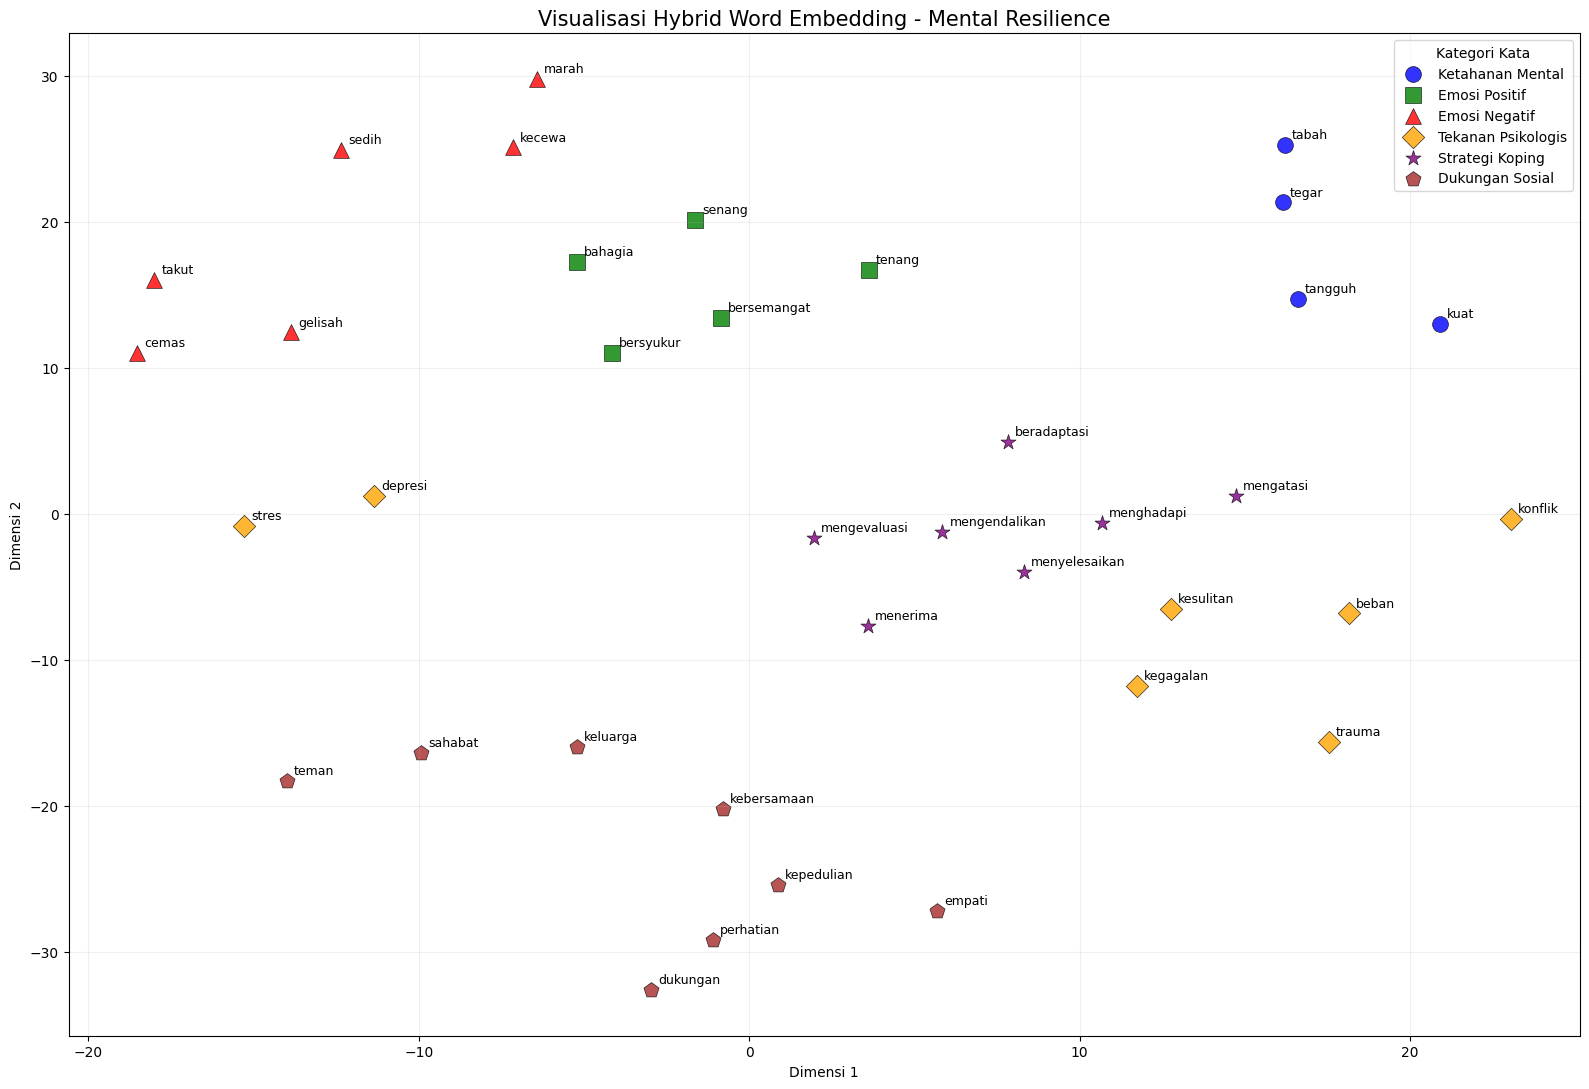

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Warna dan simbol setiap kelompok
group_styles = {
    "Ketahanan Mental": {
        "color": "blue",
        "marker": "o"
    },
    "Emosi Positif": {
        "color": "green",
        "marker": "s"
    },
    "Emosi Negatif": {
        "color": "red",
        "marker": "^"
    },
    "Tekanan Psikologis": {
        "color": "orange",
        "marker": "D"
    },
    "Strategi Koping": {
        "color": "purple",
        "marker": "*"
    },
    "Dukungan Sosial": {
        "color": "brown",
        "marker": "p"
    }
}

plt.figure(figsize=(16, 11))

# Visualisasi setiap kelompok
for group, terms in word_groups.items():

    # Mengambil indeks kata berdasarkan kelompok
    indices = [
        i for i, word in enumerate(valid_words)
        if word in terms
    ]

    if not indices:
        continue

    # Mengambil koordinat t-SNE
    x = vectors_2d[indices, 0]
    y = vectors_2d[indices, 1]

    # Style kelompok
    style = group_styles[group]

    plt.scatter(
        x,
        y,
        c=style["color"],
        marker=style["marker"],
        s=130,
        alpha=0.8,
        label=group,
        edgecolors="black",
        linewidths=0.5
    )

    # Memberikan label kata
    for i in indices:
        plt.annotate(
            valid_words[i],
            (vectors_2d[i, 0], vectors_2d[i, 1]),
            fontsize=9,
            xytext=(5, 5),
            textcoords="offset points"
        )

plt.title(
    "Visualisasi Hybrid Word Embedding - Mental Resilience",
    fontsize=15
)

plt.xlabel("Dimensi 1")
plt.ylabel("Dimensi 2")

plt.legend(
    title="Kategori Kata",
    loc="best",
    fontsize=10
)

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()